# L11 Extra — Make Your Own Magic Eye (and Crack It)
**MCS 3950 Computer Vision · UPEI · Fall 2026**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andrewgodbout/MCS-3950-Sandbox/blob/main/Notebooks/L11-Stereo/L11_MagicEye.ipynb)

The L11 warm-up hid a raised "3D" inside a picture of coloured dots. In this notebook you will
make pictures like that yourself, see why they work, and then get the computer to read them
with the **block matching** from the lecture.

Nothing to download: every picture is made from scratch. Each section is short. Run the cells
in order.

| Section | Topic |
|---------|-------|
| 1 | How to look at a magic eye |
| 2 | Why a narrower repeat looks nearer: the geometry |
| 3 | Make one, line by line |
| 4 | Hide other shapes |
| 5 | Crack it with block matching |
| 6 | Repetition: the second dip |
| 7 | Tilt your head: why the rows must line up |
| 8 | Try it |

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
GOLD, RED, TEAL, GREEN, NAVY, PURPLE, GREY = ("#C8962C", "#B82828", "#1A7A8A", "#2E7D50",
                                              "#1A3A5C", "#7B4EA0", "#7A8FA6")
print(f"OpenCV {cv2.__version__}, NumPy {np.__version__}")

OpenCV 5.0.0, NumPy 2.5.3


---
## 1 · How to look at a magic eye

A magic eye (an *autostereogram*) is a pattern that **repeats along each row**. To see the
hidden shape:

1. Bring your face close to the screen and look at the **two dots** above the picture.
2. Relax your eyes as if you were looking at something far **behind** the screen. The dots
   blur and double.
3. Lean back slowly until the middle two of the doubled dots overlap and you see **three**
   dots. Hold that.
4. Move your gaze down into the picture without refocusing. The shape appears after a few
   seconds.

Each eye is now looking at a *different copy* of the pattern, one repeat apart. Your brain
assumes both eyes are looking at the same thing, so it has to place that thing behind the
screen.

The cell below makes one with the letters **CV** hidden in it. Sections 3 and 4 explain how.

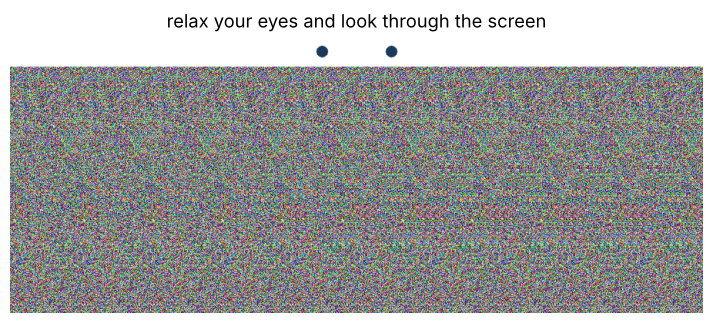

In [3]:
def depth_from_text(text, W=900, H=320):
    # a depth map: 0 = background, 1 = the raised letters
    D = np.zeros((H, W), np.uint8)
    font, scale, thick = cv2.FONT_HERSHEY_DUPLEX, 6, 28
    (tw, th), _ = cv2.getTextSize(text, font, scale, thick)
    cv2.putText(D, text, ((W - tw) // 2, (H + th) // 2), font, scale, 255, thick, cv2.LINE_AA)
    return D.astype(np.float32) / 255

def make_magic_eye(depth, repeat=90, pop=12, seed=0):
    # repeat: pattern width for the background (px); pop: how much narrower the nearest parts are (px)
    H, W = depth.shape
    img = np.random.default_rng(seed).integers(0, 256, (H, W, 3)).astype(np.uint8)  # random coloured dots
    sep = np.round(repeat - pop * depth).astype(int)       # nearer -> narrower repeat
    for x in range(W):                                     # left to right across every row
        s = sep[:, x]
        ok = x >= s                                        # (the first repeat stays random)
        img[ok, x] = img[ok, x - s[ok]]                    # copy the pixel one repeat to the left
    return img, sep

def show_magic_eye(img, repeat, title=""):
    # shown at 1 image pixel per screen pixel, with two guide dots one repeat apart on top
    band = np.full((40, img.shape[1], 3), 255, np.uint8)
    c = img.shape[1] // 2
    for x in (c - repeat // 2, c + repeat // 2):
        cv2.circle(band, (x, 20), 7, (26, 58, 92), -1, cv2.LINE_AA)
    plt.figure(figsize=(img.shape[1] / 100, (img.shape[0] + 40) / 100))
    plt.imshow(np.vstack([band, img])); plt.axis("off"); plt.title(title)
    plt.show()

DEPTH = depth_from_text("CV")
ME, SEP = make_magic_eye(DEPTH)
show_magic_eye(ME, 90, "relax your eyes and look through the screen")

**Can't see it?** Most people need a few tries. It is easier on a laptop than a phone, and
easier with the picture at full size (don't zoom the page). About 1 person in 20 can't fuse
stereo pictures at all, and that's fine: the rest of the notebook doesn't need it.

**Crossed eyes instead?** If you cross your eyes (look at a point *in front of* the screen)
you can also fuse it, but the depth comes out **inside out**: the letters sink in instead of
popping out. Section 2 shows why.

---
## 2 · Why a narrower repeat looks nearer: the geometry

In the lecture, a **closer** point has a **bigger** disparity ($Z = fB/d$). In a magic eye, a
**closer** part has a **narrower** repeat. These look like opposite rules. They are not,
because the repeat is not the disparity.

Put your eyes a distance $E$ apart (about 6.5 cm), the screen a distance $D$ in front of you,
and a hidden point behind the screen at distance $Z$ from your eyes. Draw a line from each eye
to the hidden point. The two lines cross the screen at two dots, and the gap between those dots
is what the picture has to repeat:

$$\text{repeat } s \;=\; E - \frac{E\,D}{Z}$$

(Similar triangles, as on the lecture's $Z = fB/d$ slide: the gap between the two lines shrinks
from $E$ at your eyes to $0$ at the point, in proportion to the distance left to go.)

The term $\dfrac{E\,D}{Z}$ is exactly the camera formula $\dfrac{f\,B}{Z}$: the eyes are the
baseline ($B = E$) and the screen plays the image plane ($f = D$). So

$$\boxed{\text{repeat} \;=\; \text{eye spacing} \;-\; \text{disparity}}$$

* **Closer** point → **bigger** disparity → **smaller** repeat. The two lines of sight meet
  sooner, so they are closer together when they cross the screen.
* Point far away ($Z \to \infty$) → disparity $0$ → repeat $= E$ (the lines are parallel).
* Point on the screen ($Z = D$) → disparity $E$ → repeat $0$ (both eyes look at one dot).

The figure draws it for a far point (gold) and a nearer point (teal).

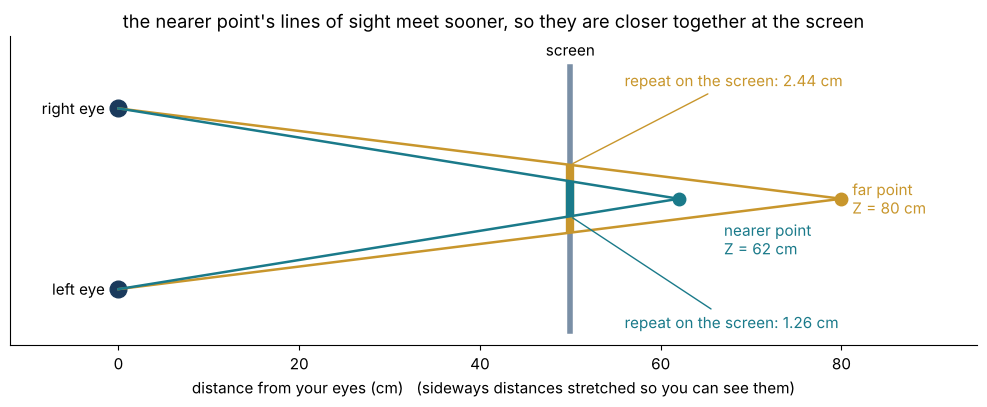

              Z (cm)   disparity E·D/Z   repeat E − E·D/Z   sum
      infinity           0.00 cm           6.50 cm     6.5 cm
            80           4.06 cm           2.44 cm     6.5 cm
            62           5.24 cm           1.26 cm     6.5 cm
            55           5.91 cm           0.59 cm     6.5 cm
            50           6.50 cm           0.00 cm     6.5 cm


In [4]:
E, D = 6.5, 50.0                                  # eye spacing and distance to the screen (cm)

def repeat_on_screen(Z):
    return E - E * D / Z

fig, ax = plt.subplots(figsize=(10, 4.2))
for eye in (0, E):
    ax.plot(0, eye, "o", color=NAVY, ms=12)
ax.text(-1.5, 0, "left eye", ha="right", va="center"); ax.text(-1.5, E, "right eye", ha="right", va="center")
ax.plot([D, D], [-1.5, E + 1.5], color=GREY, lw=4); ax.text(D, E + 1.9, "screen", ha="center")
for Z, col, name in ((80, GOLD, "far point"), (62, TEAL, "nearer point")):
    P = (Z, E / 2)                                 # hidden point straight ahead, behind the screen
    for eye in (0, E):
        ax.plot([0, P[0]], [eye, P[1]], color=col, lw=1.8)
    s = repeat_on_screen(Z)
    lo, hi = E / 2 - s / 2, E / 2 + s / 2           # where the two lines cross the screen
    ax.plot([D, D], [lo, hi], color=col, lw=6, solid_capstyle="butt")
    ax.plot(*P, "o", color=col, ms=9)
    if Z == 80: ax.text(Z + 1.2, E / 2, f"{name}\nZ = {Z} cm", va="center", color=col)
    else:       ax.text(Z + 5, E / 2 - 0.8, f"{name}\nZ = {Z} cm", ha="left", va="top", color=col)
    far = Z == 80                                   # label the far repeat above, the near one below
    ax.annotate(f"repeat on the screen: {s:.2f} cm", xy=(D, hi if far else lo),
                xytext=(D + 6, E + 1.0 if far else -1.2), color=col, va="center",
                arrowprops=dict(arrowstyle="-", color=col, lw=1))
ax.set_xlabel("distance from your eyes (cm)   (sideways distances stretched so you can see them)"); ax.set_yticks([])
ax.set_xlim(-12, 95); ax.set_ylim(-2, E + 2.6)
ax.set_title("the nearer point's lines of sight meet sooner, so they are closer together at the screen")
plt.tight_layout(); plt.show()

print("              Z (cm)   disparity E·D/Z   repeat E − E·D/Z   sum")
for Z in (1e9, 80, 62, 55, 50):
    d = E * D / Z
    print(f"{'infinity' if Z > 1e6 else Z:>14}   {d:12.2f} cm   {E - d:12.2f} cm     {E:.1f} cm")

**Disparity + repeat always add up to the eye spacing.** So "narrower repeat → nearer" in a
magic eye and "bigger disparity → nearer" in a stereo camera are the same rule.

**Crossed eyes flip it.** With crossed eyes the lines of sight cross *in front of* the screen,
and each eye looks at the copy on the *other* side. Now a narrower repeat means the lines cross
closer to the screen, which is *farther* from you, so the letters sink in.

**How far behind your screen is it?** Turn the repeat (px) into cm, then solve the box above
for $Z = \dfrac{E\,D}{E - s}$. The pixel size below is a typical laptop; hold a ruler to your
screen to get yours.

In [5]:
px_per_cm = 38          # typical laptop at 100% zoom; measure yours
D = 50.0                # how far your eyes are from the screen (cm)

for name, s_px in (("background", 90), ("letters", 90 - 12)):
    s = s_px / px_per_cm
    Z = E * D / (E - s)
    print(f"{name:10s}: repeat {s_px} px = {s:.2f} cm  →  Z = {Z:.1f} cm from your eyes, "
          f"{Z - D:.1f} cm behind the screen")

background: repeat 90 px = 2.37 cm  →  Z = 78.7 cm from your eyes, 28.7 cm behind the screen
letters   : repeat 78 px = 2.05 cm  →  Z = 73.1 cm from your eyes, 23.1 cm behind the screen


---
## 3 · Make one, line by line

`make_magic_eye` (section 1) needs only two things: a **depth map** and a **repeat width**.

* The **depth map** is a grey image the size of the picture: 0 for the background, 1 for the
  nearest parts, anything in between for in-between depths. `depth_from_text` makes one from
  some letters.
* Every pixel gets a **repeat**: `repeat − pop × depth`. The background repeats every 90 px;
  the letters (depth 1) every 90 − 12 = 78 px.
* Start from **random coloured dots**. Then go across each row from left to right and replace
  each pixel with a **copy of the pixel one repeat to its left**. Where the repeat is 90, the
  row repeats every 90 px; where it is 78, it repeats every 78 px.

That's all. Each row is built on its own and never looks at the rows above or below.

Below: the depth map, the picture, and the repeat at every pixel. Put your own initials in.

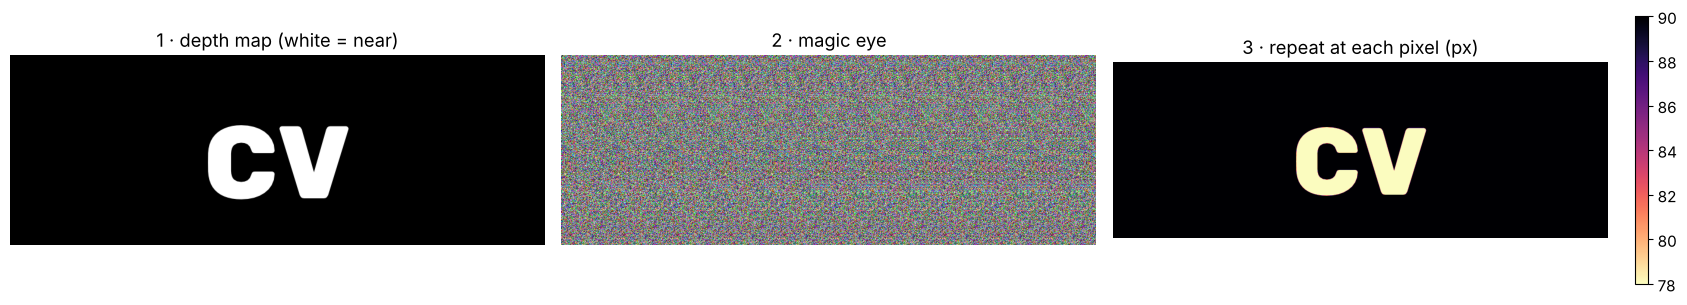

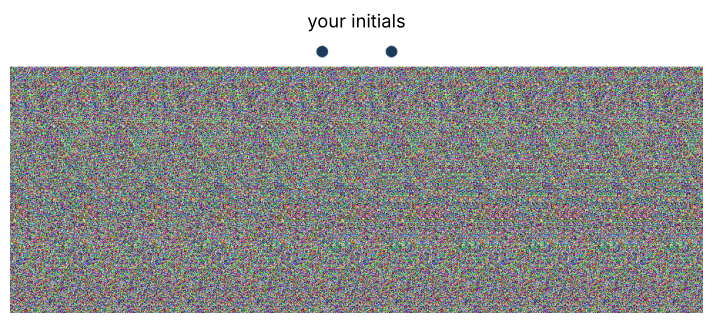

In [6]:
DEPTH = depth_from_text("CV")              # ← your initials here (2–3 letters fit)
ME, SEP = make_magic_eye(DEPTH, repeat=90, pop=12)

fig, axes = plt.subplots(1, 3, figsize=(17, 3.4))
axes[0].imshow(DEPTH, cmap="gray"); axes[0].set_title("1 · depth map (white = near)")
axes[1].imshow(ME); axes[1].set_title("2 · magic eye")
im = axes[2].imshow(SEP, cmap="magma_r"); axes[2].set_title("3 · repeat at each pixel (px)")
plt.colorbar(im, ax=axes[2], fraction=0.025)
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

show_magic_eye(ME, 90, "your initials")

**Things to try** (change the numbers, re-run):

* `pop=12` → `pop=25`: the letters stand out further. Too big (around 40) and the edges break
  up and it gets hard to fuse.
* `repeat=90` → `repeat=150`: a wider repeat sits further behind the screen. Past your eye
  spacing in pixels (about 6.5 × 38 ≈ 250 px) you can't fuse it at all, because your eyes
  would have to point *outward*. (The 1958 air photos in the lecture were too far apart for
  the same reason.)
* `seed=0` → any other number: new random dots, same hidden shape.

The warm-up picture used a more careful, symmetric version of this loop (Thimbleby, Inglis &
Witten, 1994) that splits each repeat evenly on both sides of a pixel. It gives cleaner edges;
the idea is the same.

---
## 4 · Hide other shapes

Any grey image works as a depth map, and grey levels between 0 and 1 give in-between depths.
Here are four: **steps** (a stepped pyramid), a **dome**, a **ramp** (a tilted plane) and
**ripples**.

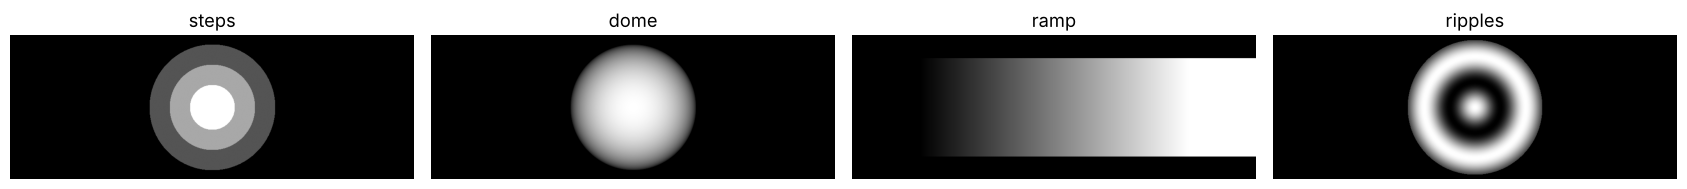

In [7]:
H, W = 320, 900
yy, xx = np.mgrid[0:H, 0:W].astype(np.float32)
r = np.hypot(xx - W / 2, yy - H / 2)                      # distance from the centre

SHAPES = {
    "steps":   np.select([r < 50, r < 95, r < 140], [1.0, 0.66, 0.33], 0.0),
    "dome":    np.sqrt(np.clip(1 - (r / 140) ** 2, 0, 1)),
    "ramp":    np.clip((xx - 150) / (W - 300), 0, 1) * (np.abs(yy - H / 2) < 110),
    "ripples": 0.5 + 0.5 * np.cos(r / 18) * (r < 150),
}
SHAPES["ripples"][r >= 150] = 0

fig, axes = plt.subplots(1, 4, figsize=(17, 2.4))
for a, (name, Dm) in zip(axes, SHAPES.items()):
    a.imshow(Dm, cmap="gray", vmin=0, vmax=1); a.set_title(name); a.axis("off")
plt.tight_layout(); plt.show()

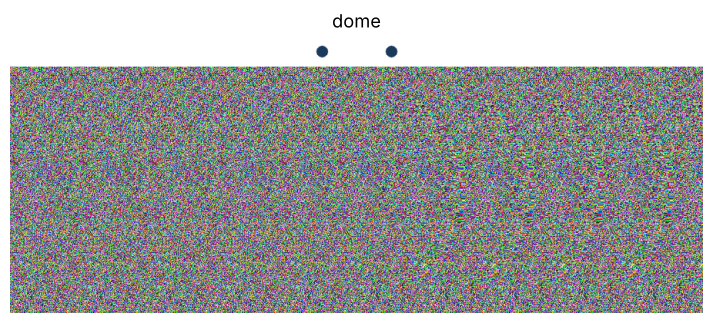

In [8]:
CHOICE = "dome"                            # ← "steps", "dome", "ramp" or "ripples"
ME_SHAPE, SEP_SHAPE = make_magic_eye(SHAPES[CHOICE], repeat=90, pop=16, seed=3)
show_magic_eye(ME_SHAPE, 90, CHOICE)

**Your own drawing.** In Colab, draw a shape in any paint program (white on black; white =
near), save it as a PNG, set `USE_UPLOAD = True` and run the cell. A photo usually doesn't
work well: brightness in a photo is not depth, so you get a confusing shape. Simple silhouettes
and soft gradients work best.

In [9]:
USE_UPLOAD = False
if USE_UPLOAD:
    from google.colab import files
    name = next(iter(files.upload()))
    pic = cv2.imread(name, cv2.IMREAD_GRAYSCALE)
    pic = cv2.resize(pic, (900, int(900 * pic.shape[0] / pic.shape[1])), interpolation=cv2.INTER_AREA)
    pic = cv2.GaussianBlur(pic.astype(np.float32) / 255, (0, 0), 2)   # soften the edges a little
    ME_MINE, _ = make_magic_eye(pic, repeat=90, pop=16, seed=4)
    show_magic_eye(ME_MINE, 90, name)

---
## 5 · Crack it with block matching

Your brain found the shape by lining up copies of the pattern. The computer can do the same with
the lecture's **block matching**, with one change: there is only one picture, so we compare it
**with itself**, shifted along the row.

For every pixel, and for every shift $d$ in a search range:

1. take a small window around the pixel,
2. take the window $d$ pixels to its **left** in the same picture,
3. score the pair with **SAD** (sum of absolute differences; here the mean, which ranks the
   same way),
4. keep the shift with the **lowest** score.

The winning shift is the repeat at that pixel, and the repeat tells us the depth:
$\text{depth} = (\text{repeat}_{\text{background}} - d)\,/\,\text{pop}$.

exact repeat recovered at 99.5% of pixels


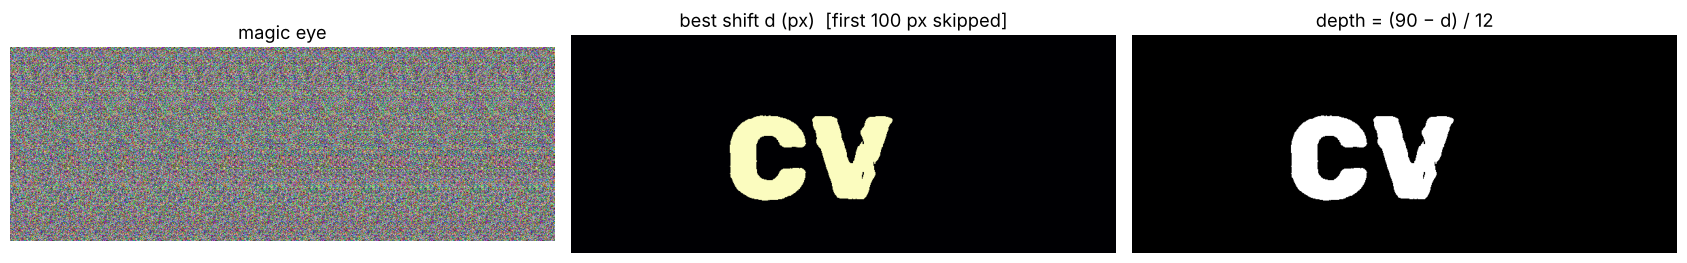

In [10]:
def crack(img, dmin, dmax, w=9):
    # block matching of an image against itself, along the rows: the best shift d at every pixel
    G = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY).astype(np.float32)
    best = np.full(G.shape, np.inf); D = np.zeros(G.shape, int)
    for d in range(dmax, dmin - 1, -1):                    # largest shift first: on a tie, keep it
        diff = np.full_like(G, 255.0)
        diff[:, d:] = np.abs(G[:, d:] - G[:, :-d])         # pixel x against pixel x − d
        cost = cv2.boxFilter(diff, -1, (w, w))             # SAD over a w × w window (as a mean)
        better = cost < best
        best[better] = cost[better]; D[better] = d
    return D

FOUND = crack(ME, 70, 100)                 # search 70–100 px: covers 78 and 90, below two repeats
inside = np.zeros(FOUND.shape, bool); inside[:, 100:] = True   # the first repeat is random: skip it
print(f"exact repeat recovered at {np.mean((FOUND == SEP)[inside]):.1%} of pixels")

DEPTH_FOUND = (90 - FOUND) / 12
fig, axes = plt.subplots(1, 3, figsize=(17, 3.4))
axes[0].imshow(ME); axes[0].set_title("magic eye")
axes[1].imshow(FOUND[:, 100:], cmap="magma_r"); axes[1].set_title("best shift d (px)  [first 100 px skipped]")
axes[2].imshow(DEPTH_FOUND[:, 100:], cmap="gray"); axes[2].set_title("depth = (90 − d) / 12")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

Nearly every pixel is exactly right, because a program made the picture exact: every copy is a
perfect copy. On real photos (the lecture's drone pair) the same code is wrong at several percent
of pixels: brightness changes, noise, blank roofs and repeating patterns (next section).

Try `crack` on your section 4 shape: `crack(ME_SHAPE, 70, 100)` (with `pop=16` the repeat goes
down to 74).

---
## 6 · Repetition: the second dip

A magic eye repeats **on purpose**, so a shift of **two** repeats lines up perfectly too, and
so does three. The cost curve below is the SAD for every shift from 10 to 200 px, at one
background pixel and one letter pixel. Each has a dip at its repeat and another at twice its
repeat.

This is the lecture's **ribbed roof**: a pattern that repeats along the row gives several
equally good matches. That's why `crack` searched only 70–100 px, below two repeats. Your
eyes have the same problem: sometimes they lock on two repeats apart, and you see a deeper,
stretched version of the picture.

background pixel: first dip at 90 px, second dip at 180 px
letter pixel: first dip at 78 px, second dip at 168 px


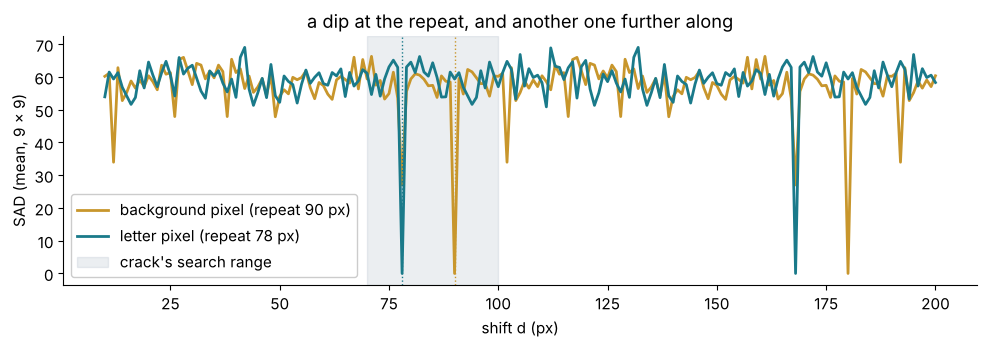

In [11]:
G = cv2.cvtColor(ME, cv2.COLOR_RGB2GRAY).astype(np.float32)
ys, xs = np.nonzero((DEPTH > 0.99) & inside)
pixels = {"background": (160, 860), "letter": (ys[len(ys) // 2], xs[len(xs) // 2])}

shifts = np.arange(10, 201)
fig, ax = plt.subplots(figsize=(10, 3.6))
for (name, (y, x)), col in zip(pixels.items(), (GOLD, TEAL)):
    cost = [np.abs(G[y-4:y+5, x-4:x+5] - G[y-4:y+5, x-d-4:x-d+5]).mean() for d in shifts]
    ax.plot(shifts, cost, color=col, lw=2, label=f"{name} pixel (repeat {SEP[y, x]} px)")
    ax.axvline(SEP[y, x], color=col, ls=":", lw=1)
    far = shifts > SEP[y, x] + 20                          # look past the first dip for the second
    print(f"{name} pixel: first dip at {SEP[y, x]} px, second dip at {shifts[far][np.argmin(np.array(cost)[far])]} px")
ax.axvspan(70, 100, color=GREY, alpha=0.15, label="crack's search range")
ax.set_xlabel("shift d (px)"); ax.set_ylabel("SAD (mean, 9 × 9)")
ax.set_title("a dip at the repeat, and another one further along")
ax.legend(loc="lower left", framealpha=1); plt.tight_layout(); plt.show()

The background pixel's second dip is at 180 = 2 × 90. The letter pixel's is at **168**, not
2 × 78 = 156. One repeat to its left (78 px) it has landed on the background, and the
background copies from 90 px further left: 78 + 90 = 168. The second dip is always "one more
copy to the left", whatever that copy's repeat is.

---
## 7 · Tilt your head: why the rows must line up

Tilt your head while looking at a magic eye and the shape vanishes. Each row was built on its
own, so the matching copy is **on the same row**, and only on the same row. These rows are the
**epipolar lines** from the lecture.

Below, we rotate the picture by a small angle (the same as tilting your head) and crack it again
with the same row-by-row search. Then we rotate it back, which is **rectifying**: lining the rows
up again before matching.

tilt     rows off after one repeat    pixels within 1 px of the right shift
   0°              0.0 px                     99%
0.25°              0.4 px                     98%


 0.5°              0.8 px                     76%
   1°              1.6 px                      8%
   2°              3.1 px                      9%


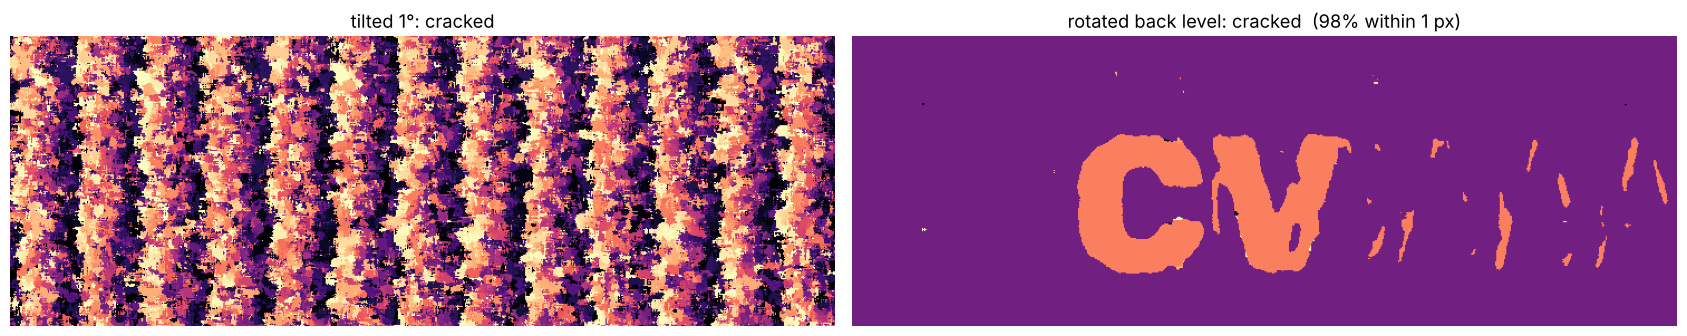

In [12]:
H, W = ME.shape[:2]
check = np.zeros((H, W), bool); check[30:-30, 130:-30] = True     # stay away from the borders

def tilt(img, deg, interp):
    R = cv2.getRotationMatrix2D((W / 2, H / 2), deg, 1)
    return cv2.warpAffine(img, R, (W, H), flags=interp, borderMode=cv2.BORDER_REFLECT)

print("tilt     rows off after one repeat    pixels within 1 px of the right shift")
for deg in (0, 0.25, 0.5, 1, 2):
    T = crack(tilt(ME, deg, cv2.INTER_LINEAR), 70, 100)
    truth = tilt(SEP.astype(np.float32), deg, cv2.INTER_NEAREST)
    print(f"{deg:4}°     {90 * np.sin(np.radians(deg)):12.1f} px            "
          f"{np.mean((np.abs(T - truth) <= 1)[check]):12.0%}")

TILTED = tilt(ME, 1, cv2.INTER_LINEAR)
BACK = tilt(TILTED, -1, cv2.INTER_LINEAR)                # rectify: rotate it level again
fig, axes = plt.subplots(1, 2, figsize=(17, 3.4))
for a, img, t in ((axes[0], TILTED, "tilted 1°: cracked"), (axes[1], BACK, "rotated back level: cracked")):
    F = crack(img, 70, 100)
    acc = np.mean((np.abs(F - SEP) <= 1)[check]) if img is BACK else None
    a.imshow(F[30:-30, 130:-30], cmap="magma_r", vmin=70, vmax=100)
    a.set_title(t + (f"  ({acc:.0%} within 1 px)" if acc is not None else "")); a.axis("off")
plt.tight_layout(); plt.show()

One degree is enough to ruin it: one repeat to the left, the matching copy is now about 1.6 rows
up or down, and the random dots there are completely different. Rotating back brings the rows
level and the match returns, a little worse than before because rotating twice blurs the dots.
The streaks to the right of the letters are the blur's fault: the background there still holds
copies of the letters' pattern, and with blurred dots the letters' 78 px shift sometimes
narrowly beats the true 90 px.

This is the lecture's **rectification** slide in miniature. A real stereo rig is never perfectly
level, so before row-by-row matching both images are warped so that every match is on its row.
The magic eye never needs it: it is level by construction.

---
## 8 · Try it

Not graded.

**A — Crack a classmate's magic eye.** Hide your initials (section 3), save the picture with
`plt.imsave("mine.png", ME)`, and send a classmate **the image only**, not the repeat or `pop`.
Crack theirs with `crack`. You'll need to choose the search range without being told the
repeat. *Hint:* plot the cost curve (section 6) at a few pixels; the first dip is the background
repeat. What happens if your range includes two repeats?

**B — Distance check.** Your screen has 40 px per cm and you sit 60 cm from it. A magic eye has a
120 px repeat. How far behind the screen does the background appear? What repeat would put a
shape 10 cm closer to you than that? (Use $s = E - ED/Z$ with $E = 6.5$ cm.)

**C — Inside out.** Make a magic eye from `1 - DEPTH` instead of `DEPTH`. Before you look:
will the letters pop out or sink in? Check by looking, then by cracking it. Then look at the
*original* one with crossed eyes (section 1) and compare.

**D — Back to real photos.** In the main L11 notebook, the drone pair's block matching is wrong at
several percent of pixels; here it's almost perfect. List three things that are true of a magic
eye and false of the drone photos.

<details><summary><b>Answer to B</b> (click)</summary>

$s = 120/40 = 3.0$ cm, so $Z = ED/(E - s) = 6.5 \times 60 / 3.5 = 111.4$ cm from your eyes:
**51.4 cm behind the screen**.
10 cm closer: $Z = 101.4$ cm, so $s = 6.5 - 6.5 \times 60/101.4 = 2.65$ cm $= 106$ px. A
narrower repeat (106 vs 120 px) for a nearer shape, as in section 2.
</details>

---
## 🔎 Explore further (optional)

* Thimbleby, Inglis & Witten (1994), *Displaying 3D images: algorithms for single-image random-dot
  stereograms*, IEEE Computer 27(10). The symmetric algorithm behind the warm-up picture, with
  hidden-surface removal.
* Béla Julesz (1960s) invented the **random-dot stereogram** (two separate dot pictures) to show
  that the brain can see depth with no shapes or edges at all: matching alone is enough.
  Christopher Tyler turned it into the single-picture version in 1979.